# 2.2.3 HUIM + freshness explainability

## 1. Business questions and course connection

**Owner:** Winston Ho Rui Wei  
**Status:** prepared for execution; report only the executed findings.

This notebook reloads the final **HUIM + freshness** pipeline. It asks which
history signals the network attends to, how explicit freshness changes its
score, and whether sensible input changes affect its predictions. It does
**not** train, tune, rerank, or modify any evaluator handoff.

The main method follows the course's **Week 8 target-aware LSTM prediction
explanations**: actual attention weights, readable item titles and observed
outcomes. Week 11's confounding audit motivates checking those explanations.
Exact score decomposition and grouped input perturbations are our project
adaptations. SHAP/LIME are named in the introductory lecture, but were not
demonstrated in the supplied materials and are not required here.

Attention weights belong to separately encoded **history events**, including their article and engagement features. We report real forward-pass weights without sharpening or
rescaling them. Event-removal checks support interpretation; attention alone
does not establish causal influence or a reader's psychological motive.


## 2. Colab setup

Select an **L4 GPU with High RAM** and use a fresh runtime. Upload
**`huim_explainability_helpers.zip`** to `/content`, leave it zipped, then
Run all. An existing A100 GPU runtime also supports the same execution path.

The live shortcut to `BT4222 Shared Final Folder` must remain under My Drive.
Both final model run folders are read for shared examples; only this
notebook's model is loaded. Helpers and fitted transformations come from
that saved model's own bundle. No GitHub credentials or original training
helper ZIP is needed.


In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import sys, json, shutil, zipfile, hashlib, importlib.util, subprocess
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT=next(p for p in [
    Path('/content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder'),
    Path('/content/drive/MyDrive/BT4222 Shared Final Folder')
] if (p/'split_manifest.json').is_file())
CODE_DIR=Path('/content/huim_explainability_code')
CODE_DIR.mkdir(parents=True,exist_ok=True)
with zipfile.ZipFile('/content/huim_explainability_helpers.zip') as archive:
    archive.extractall(CODE_DIR)
sys.path.insert(0,str(CODE_DIR))
if importlib.util.find_spec('duckdb') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','duckdb'])
import numpy as np,pandas as pd,torch
import explain_common as C
import explain_report as R
from IPython.display import display,Image,Markdown
MODEL_NAME='huim'
SOURCE_RUN=DATA_ROOT/C.MODEL_RUNS[MODEL_NAME]
SAVED_CODE=CODE_DIR/'saved_model_code'
shutil.copytree(SOURCE_RUN/'model'/'code',SAVED_CODE,dirs_exist_ok=True)
sys.path.insert(0,str(SAVED_CODE))
from huim_explain import HUIMExplainer
assert torch.cuda.is_available(),'Select a GPU runtime before running.'
DEVICE=torch.device('cuda')
torch.backends.cuda.matmul.allow_tf32=False
torch.set_float32_matmul_precision('highest')
RUN_ID=datetime.now(ZoneInfo('Asia/Singapore')).strftime('%Y%m%d_%H%M%S')+'_seed42'
OUT=Path('/content/huim_explainability_reports')/RUN_ID
PERSIST=DATA_ROOT/'Experiments'/'2.2_huim'/'2.2.3_explainability'/RUN_ID
OUT.mkdir(parents=True,exist_ok=True)
def digest(path):return hashlib.sha256(Path(path).read_bytes()).hexdigest()
source_files=[SOURCE_RUN/'model'/x for x in ['preprocessing.json','feature_dictionary.json','score_recipe.json']]
SOURCE_DIGESTS={str(p.relative_to(SOURCE_RUN)):digest(p) for p in source_files}
print('Model:',MODEL_NAME,'| GPU:',torch.cuda.get_device_name())
print('Read-only source:',SOURCE_RUN)
print('New report folder:',PERSIST)


Mounted at /content/drive
Model: huim | GPU: NVIDIA L4
Read-only source: /content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder/Experiments/2.2_huim/2.2.2_freshness_run/20261104_234712_freshness_seed42
New report folder: /content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder/Experiments/2.2_huim/2.2.3_explainability/20261105_172058_seed42


## 3. Reload the fitted pipeline

Use saved weights, named features/category maps and fitted transformations.
The LSTM bundle includes frozen article inputs. HUIM reconstructs inputs with
its saved preprocessing and shared source snapshots; its existing loader also
reconstructs other split tensors, but only validation is explained here.
There is no optimiser or preprocessing fit. Lookup IDs are used for retrieval
and joins, never treated as continuous explanatory features.


In [2]:
adapter=HUIMExplainer.load(DATA_ROOT,SOURCE_RUN,DEVICE)
requests=C.sample_requests(adapter.requests,n=200,seed=42)
adapter.set_reference(requests.behaviour_id.iloc[0])
metadata=C.load_metadata(DATA_ROOT)
sources=C.read_sources(DATA_ROOT,requests)
COHORT_DIGEST=hashlib.sha256('\n'.join(sorted(requests.behaviour_id)).encode()).hexdigest()
print('Fixed validation requests:',len(requests),'| set SHA256:',COHORT_DIGEST)
print('Saved freshness coefficient:',adapter.weight)
print('Device/account reference request:',requests.behaviour_id.iloc[0])


articles: 20,738 unique IDs from ['train_val', 'test']
vectors: text 20,720, image 16,995
recorded pairs: train 2,585,747, validation 344,666, test 348,951
inputs ready in 117s
Fixed validation requests: 200 | set SHA256: 6c10314e902db2b32234b350c063ecae956c0efdca912a8beac6efcd36dac661
Saved freshness coefficient: 2.0
Device/account reference request: 1274613:290219498


## 4. Shared explanation cohort and source-score agreement

Both notebooks select the same 200 requests using seed-42 BLAKE2b priorities
with salt `validation_explainability`. Each request contributes the union of
both final models' top3, original rank100, within-buffer neural favourite and
original known clicks. This is a **conditional explanation sample**, not a
population-wide feature-importance estimate or new performance evaluation.

Known clicked misses can enter this explanation-only pair table. The genuine
saved rankings are read-only. Shown-but-unclicked outcomes and unshown unknown
outcomes remain distinct. Every available baseline score is compared with
the actual saved exports at tolerance `1e-4` before reporting explanations.

The forward-pass outputs and supporting perturbations are calculated together
below, then interpreted in the following sections. No catalogue-wide export
or retraining is repeated.


In [3]:
pairs=C.build_pairs(requests,sources,metadata)
baseline,sensitivity,summary,attention_summary,attentions=C.explain_pairs(
    adapter,pairs,sources,MODEL_NAME,OUT)
requests[['behaviour_id','user_id','impression_id','impression_time']].to_parquet(
    OUT/'validation_requests.parquet',index=False)
parity=json.loads((OUT/'baseline_parity.json').read_text())
print('Explained pairs:',len(baseline),'| saved-score parity:',parity)
display(baseline.groupby('outcome').size().rename('pairs').to_frame())


Explained pairs: 1724 | saved-score parity: {'pairs_compared': 1723, 'max_abs_difference': 1.9073486328125e-06, 'tolerance': 0.0001, 'passed': True}


,pairs
outcome,
clicked,200
shown_not_clicked,218
unexposed_unknown,1306


## 5. Candidate-aware attention and four rule-selected cases

Choose the first qualifying request in the fixed hash order for each rule:
recovered known click, missed known click, disagreement between the models'
top recommendations, and a freshness-induced ordering change **within the
saved buffer**. A rule with no qualifying example is omitted. We do not select
the most visually persuasive examples.

Read each candidate's neural score, exact age penalty, final score, known
exposure outcome and original saved rank together with the attention plot
and top-history title table. A rank beyond the saved 200 is not known exactly.
For freshness cases, the comparison concerns the displayed articles, not the
unobserved global raw-neural ranking.

Delete one high-weight and one low-weight history event and recompute the
event pathway. Associated fields, masks and lengths remain aligned; LSTM
states and time gaps are recomputed after deletion. Separate historical
profile aggregates remain fixed, so this is event-pathway sensitivity rather
than removing all evidence that an interaction happened.


### Recovered known click

,behaviour_id,article_id,title,outcome,huim_rank_in_buffer,age_hours,neural_score,freshness_penalty,final_score
0,1274613:290219498,9774526,Asgreen drømmer om Tour-sejr: Har kunnet dufte...,clicked,3.0,1.203611,-1.918238,-1.580195,-3.498433
1,1274613:290219498,9783628,Efter 11 år: I dag kan det ske,unexposed_unknown,1.0,0.196389,-1.111248,-0.358616,-1.469863


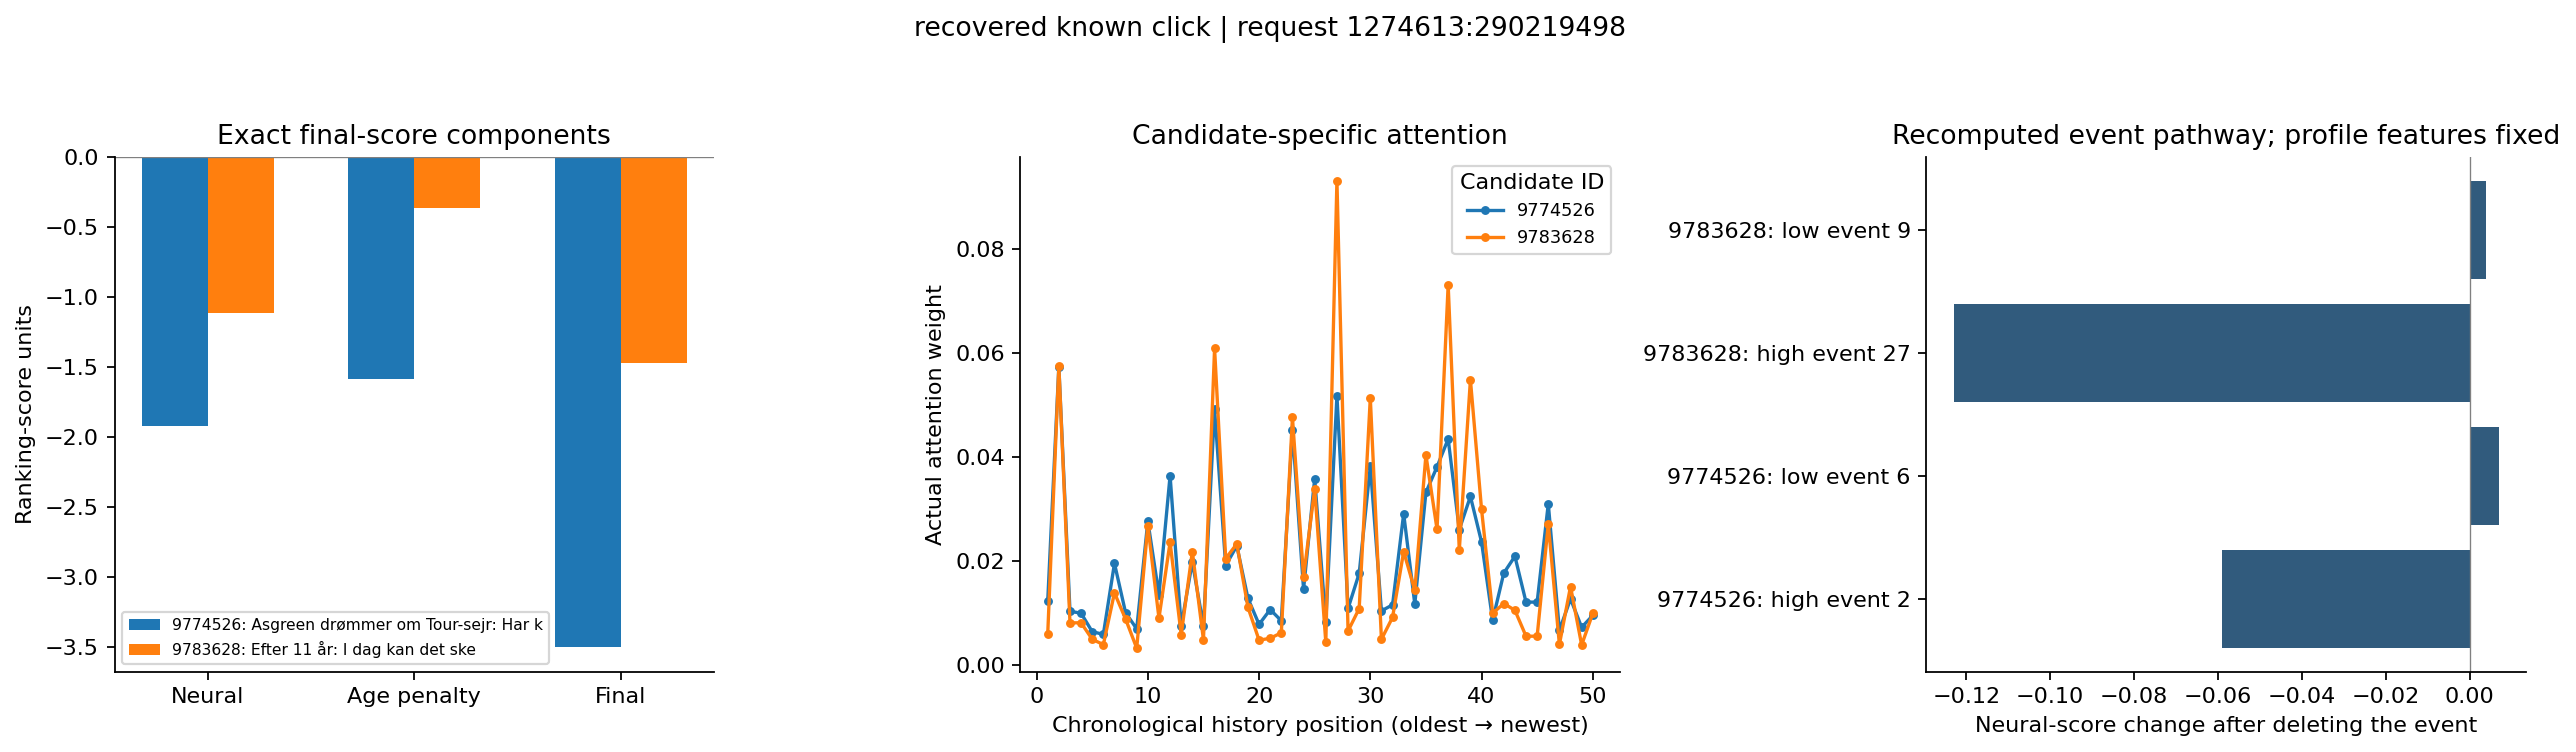

,candidate_article_id,history_position,history_title,attention_weight
0,9774526,2,Stor hyldest: Stjerne i tårer,0.057307
1,9774526,27,- En frygtelig afslutning på en fantastisk tid,0.051756
2,9774526,16,Newcastle er klar til Champions League,0.049158
3,9774526,23,Benhård straf til storklub,0.045212
4,9774526,37,Seks spillere forlader Superliga-klub,0.043409
5,9783628,27,- En frygtelig afslutning på en fantastisk tid,0.093084
6,9783628,37,Seks spillere forlader Superliga-klub,0.073050
7,9783628,16,Newcastle er klar til Champions League,0.060821
8,9783628,2,Stor hyldest: Stjerne i tårer,0.057424
9,9783628,39,Dansk toptræner suspenderet,0.054794


### Freshness ordering in buffer

,behaviour_id,article_id,title,outcome,huim_rank_in_buffer,age_hours,neural_score,freshness_penalty,final_score
2,1274613:290219498,9783628,Efter 11 år: I dag kan det ske,unexposed_unknown,1.0,0.196389,-1.111248,-0.358616,-1.469863
3,1274613:290219498,9782998,LIVE: Stadion eksploderer!,unexposed_unknown,15.0,12.710833,-0.274508,-5.236372,-5.510881


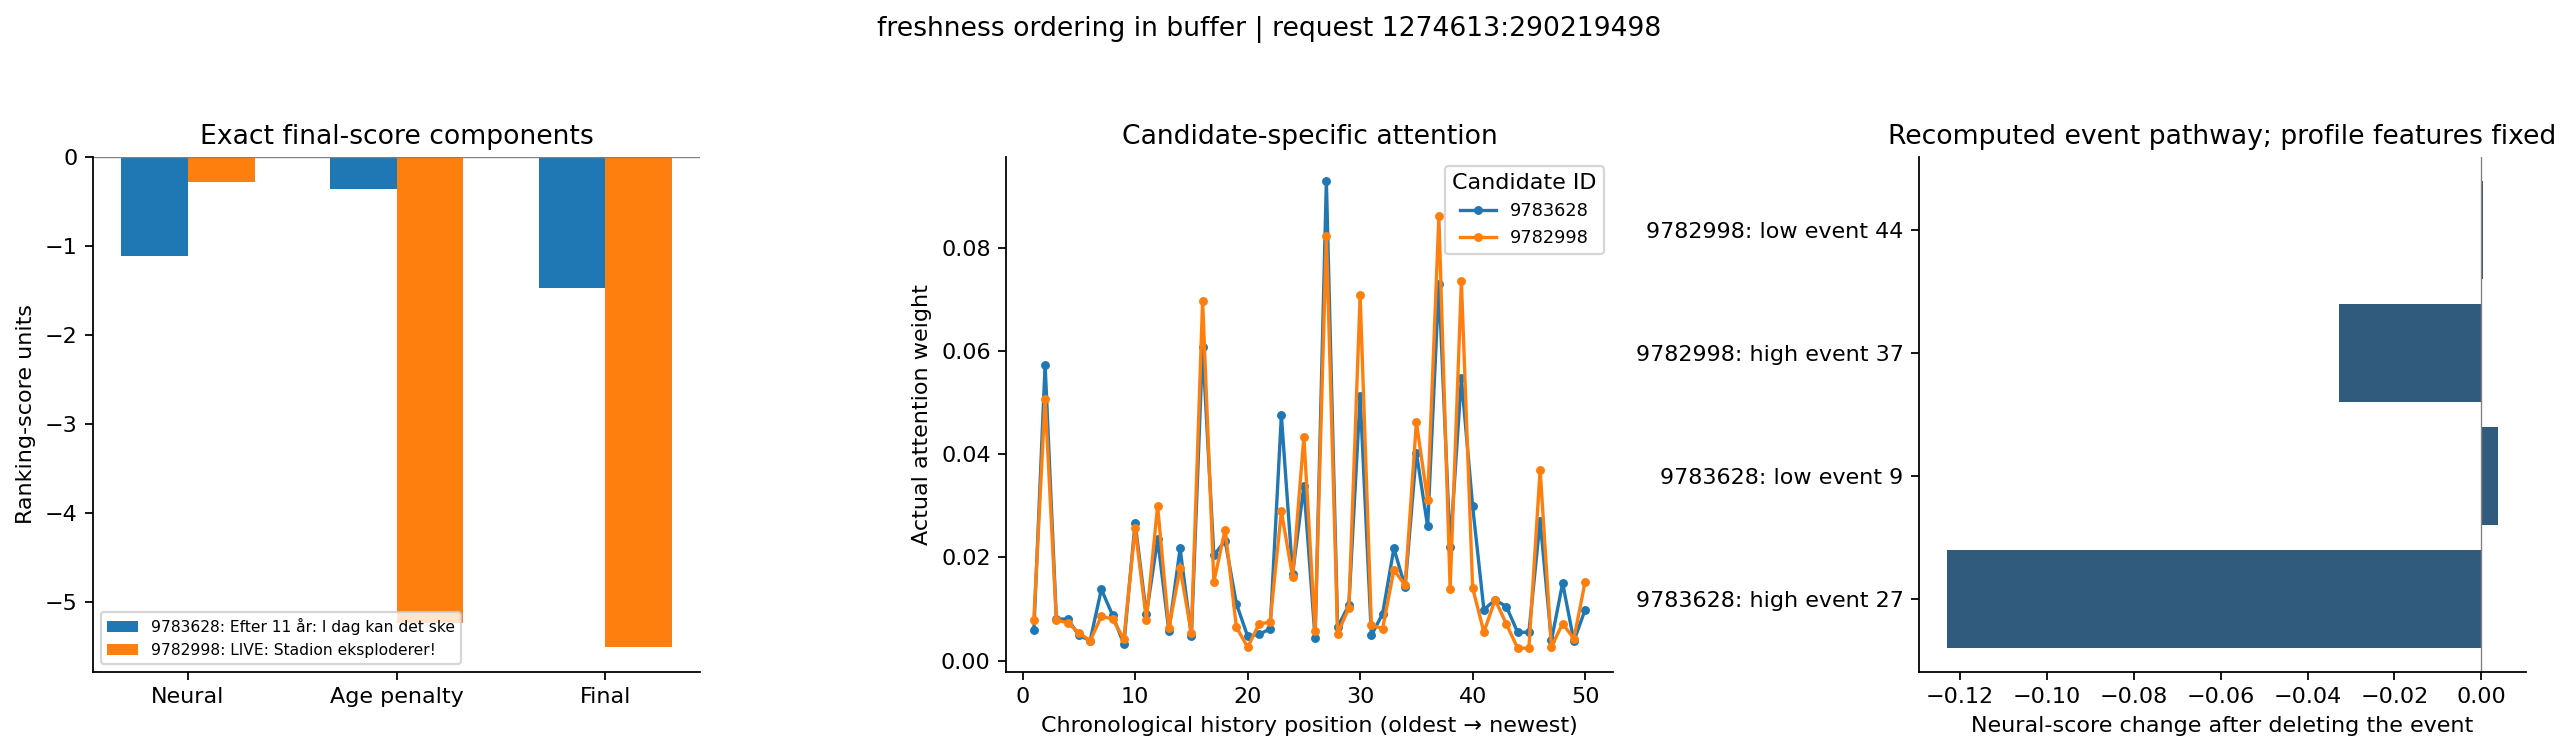

,candidate_article_id,history_position,history_title,attention_weight
10,9783628,27,- En frygtelig afslutning på en fantastisk tid,0.093084
11,9783628,37,Seks spillere forlader Superliga-klub,0.073050
12,9783628,16,Newcastle er klar til Champions League,0.060821
13,9783628,2,Stor hyldest: Stjerne i tårer,0.057424
14,9783628,39,Dansk toptræner suspenderet,0.054794
15,9782998,37,Seks spillere forlader Superliga-klub,0.086148
16,9782998,27,- En frygtelig afslutning på en fantastisk tid,0.082324
17,9782998,39,Dansk toptræner suspenderet,0.073632
18,9782998,30,Den værst tænkelige start: Dansk selvmål i Bar...,0.070840
19,9782998,16,Newcastle er klar til Champions League,0.069778


### Model disagreement

,behaviour_id,article_id,title,outcome,huim_rank_in_buffer,age_hours,neural_score,freshness_penalty,final_score
4,692871:27656549,9788664,Bombe under opsejling: Benzema overvejer vildt...,shown_not_clicked,1.0,1.150556,-0.764372,-1.531452,-2.295825
5,692871:27656549,9789702,425.000 i løn: Svært,unexposed_unknown,2.0,0.146944,-2.105351,-0.274203,-2.379554


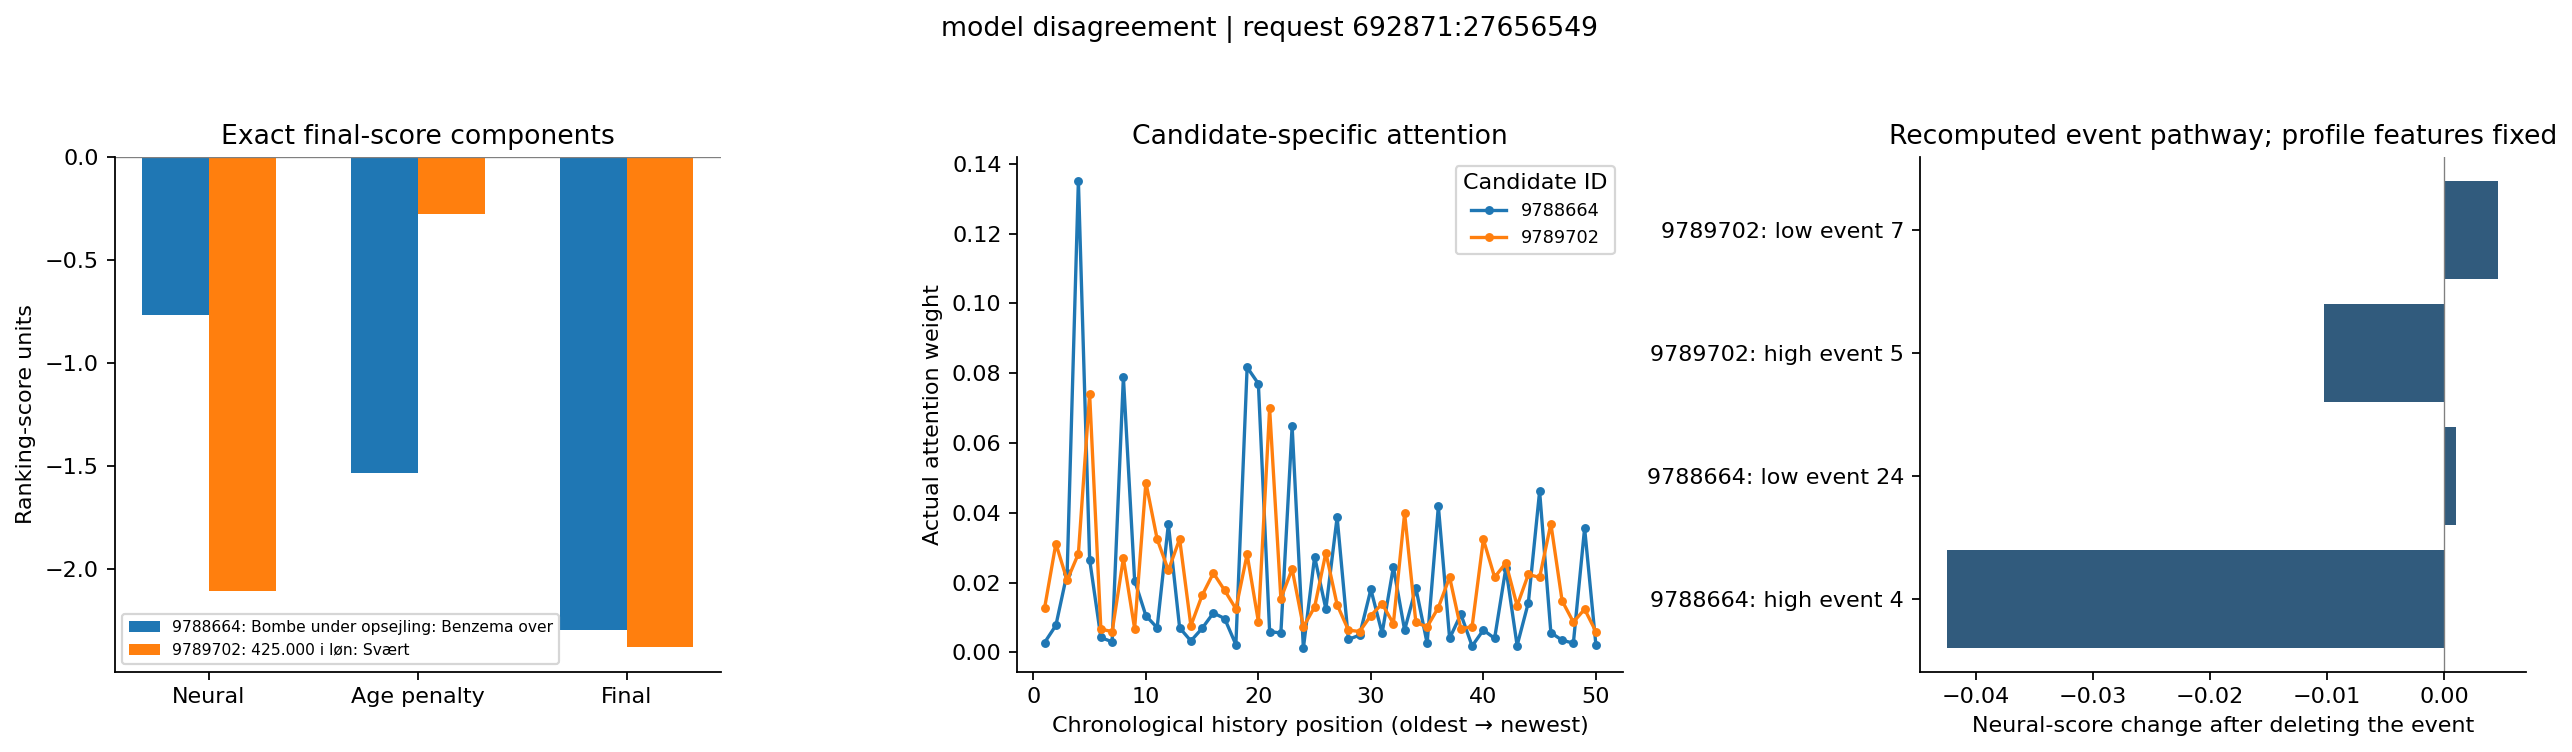

,candidate_article_id,history_position,history_title,attention_weight
20,9788664,4,Juventus får hug på banen efter pointstraf,0.135191
21,9788664,19,Den værst tænkelige start: Dansk selvmål i Bar...,0.081710
22,9788664,8,Kryptisk superstjerne: Overvejer fremtiden,0.078884
23,9788664,20,- En frygtelig afslutning på en fantastisk tid,0.076997
24,9788664,23,Raser mod FC Barcelona: Takker russerne,0.064829
25,9789702,5,Nye Schumacher-anklager: Har et problem med na...,0.074003
26,9789702,21,Messerschmidt i dyb restaurant-sorg: - Ærgerligt!,0.069909
27,9789702,10,Ville ikke mere: Løb 475 kilometer,0.048675
28,9789702,33,Grundstødt skib er trukket fri fra Suezkanalen,0.039869
29,9789702,46,Den falske telefon-myte: Du skal ikke gøre det,0.036861


### Missed known click

,behaviour_id,article_id,title,outcome,huim_rank_in_buffer,age_hours,neural_score,freshness_penalty,final_score
6,2185738:101887729,9783850,Topløst vanvid på jysk festival,clicked,170.0,40.477500,-4.016602,-7.450302,-11.466904
7,2185738:101887729,9785604,Særlig detalje bekymrer: Clara maner til ro,unexposed_unknown,1.0,0.049722,-1.818676,-0.097051,-1.915727


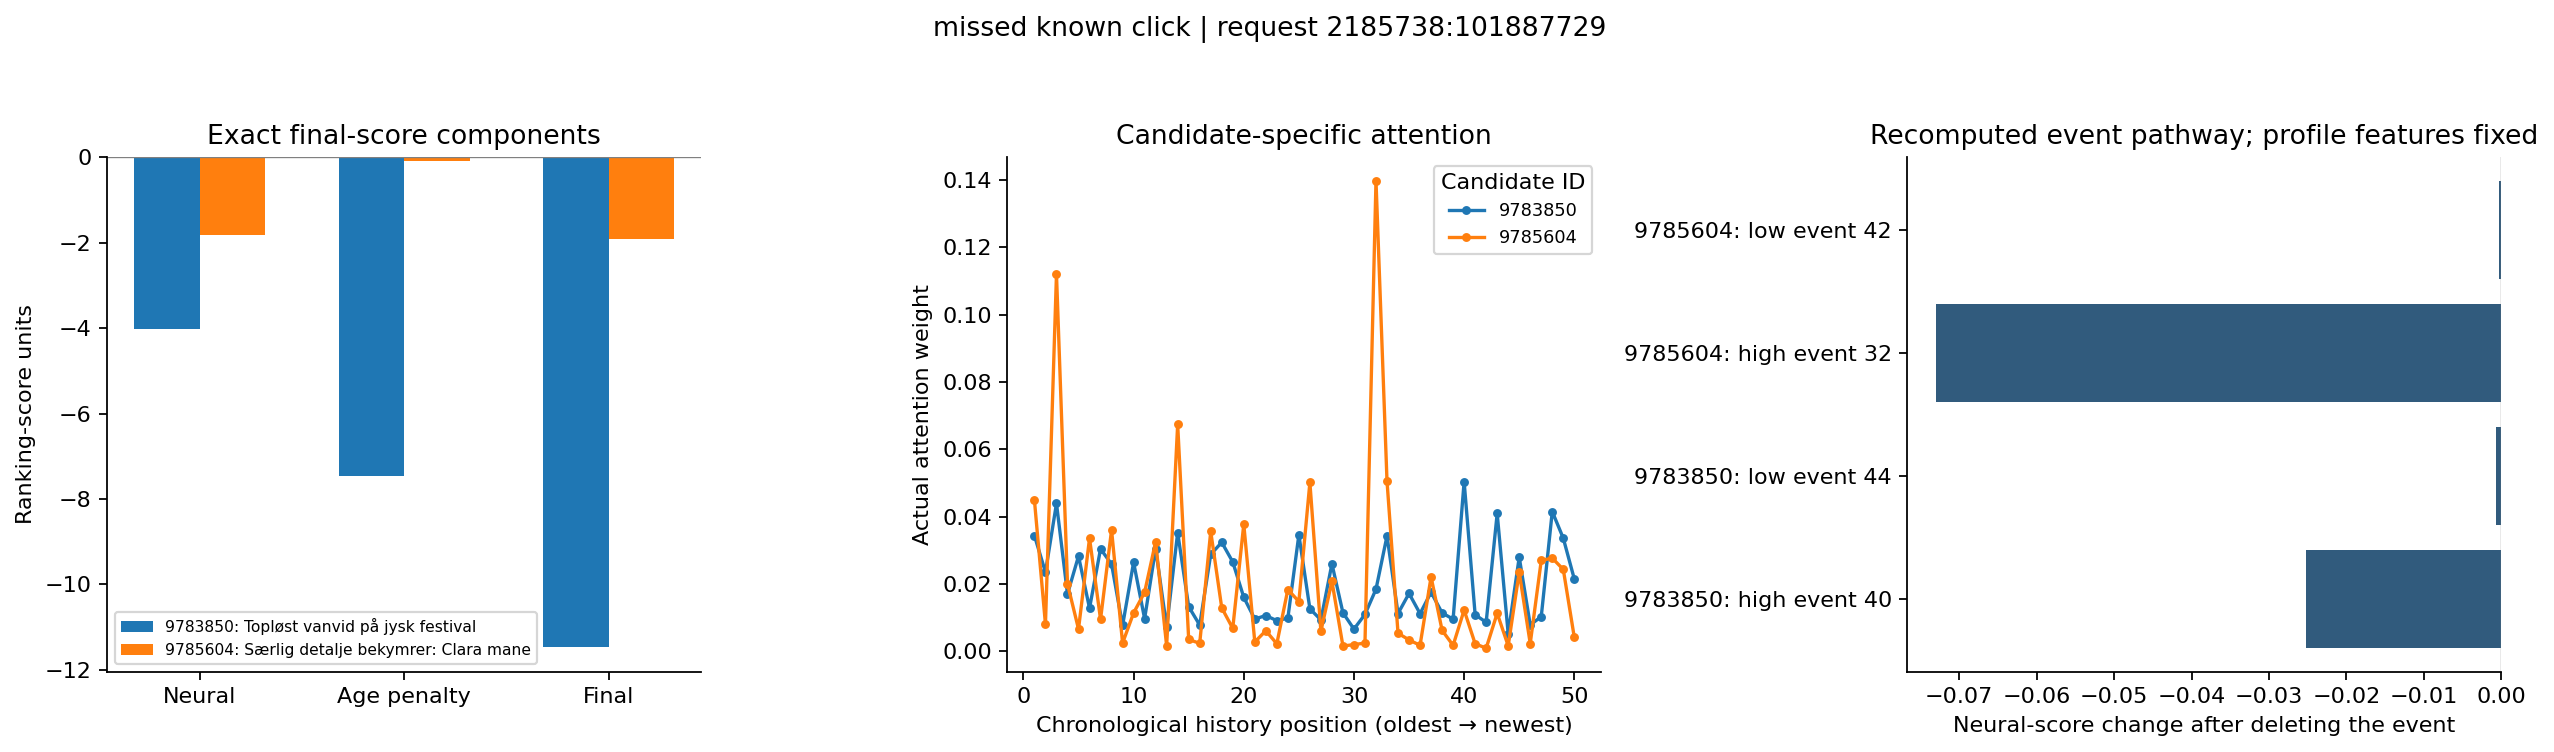

,candidate_article_id,history_position,history_title,attention_weight
30,9783850,40,Afvist på tv: Det er fandeme i orden,0.050433
31,9783850,3,Stor hyldest: Stjerne i tårer,0.043956
32,9783850,48,Gennemsigtig kjole på den røde løber: Derfor g...,0.041541
33,9783850,43,Skuffet over mændene: En dansk buffet,0.040977
34,9783850,14,Haalands mange rutiner: Men én ting gør han al...,0.035287
35,9785604,32,Kæmpe Giro-drama: Vild gyser på toppen,0.139796
36,9785604,3,Stor hyldest: Stjerne i tårer,0.112081
37,9785604,14,Haalands mange rutiner: Men én ting gør han al...,0.067415
38,9785604,33,Mourinho raser: - Det er en joke!,0.050595
39,9785604,26,LIVE: Store VM-tæsk til Danmark,0.050176


In [4]:
cases=C.choose_cases(baseline,requests,sources,MODEL_NAME)
removal=C.event_removal(adapter,cases,attentions,metadata)
coverage=R.coverage_table(adapter,metadata,requests,sources[MODEL_NAME]['rankings'])
top_history,case_candidates,variation=R.make_report(
    adapter,baseline,sensitivity,summary,attention_summary,attentions,cases,
    removal,coverage,metadata,MODEL_NAME,OUT)
histories=[]
for bid in requests.behaviour_id:
    h=adapter.history(bid).copy()
    h['behaviour_id']=bid;h['history_position']=np.arange(1,len(h)+1)
    h['title']=[C.title(metadata,a,None) for a in h.article_id]
    histories.append(h)
pd.concat(histories,ignore_index=True).to_csv(OUT/'history_events.csv',index=False)
for case in cases:
    display(Markdown('### '+case['case'].replace('_',' ').capitalize()))
    table=case_candidates[case_candidates['case']==case['case']]
    display(table[['behaviour_id','article_id','title','outcome',MODEL_NAME+'_rank_in_buffer',
                   'age_hours','neural_score','freshness_penalty','final_score']])
    display(Image(filename=str(OUT/'figures'/('case_'+case['case']+'.png'))))
    display(top_history[top_history['case']==case['case']][[
        'candidate_article_id','history_position','history_title','attention_weight']])


## 6. Supporting score-sensitivity diagnostics

These are **one-at-a-time input replacements**, not retrained ablations,
SHAP values, permutation importance or additive contributions. Positive
deltas mean the replacement raised the neural score. The chart uses mean
absolute changes with equal request weight; compare within this fitted model,
not the absolute logit scales of different models.

| Group | Declared reference |
| --- | --- |
| Text / image | Suppress the representation and its associated availability indicators in candidate and history article encoders |
| Non-temporal metadata | Existing missing/empty conventions for category, type, topics, body, sentiment and premium; preserve publication time and vector availability; HUIM's associated candidate metadata crosses become missing too |
| Event-history pathway | Use the model's empty event pathway while keeping separate profile aggregates fixed |
| Device/account context | Copy device and account fields from the first hash-selected observed request; preserve clock, candidate age and history profiles; update HUIM's subscriber-access crosses consistently |

The explicit freshness term stays fixed. Text/image effects include their
availability indicators, and correlated signals can substitute for each
other. These references are our diagnostic design choices, not a procedure
prescribed in the lectures or causal interventions on a real reader.


,group_name,mean_absolute_change,mean_signed_change,requests
0,Device/account observed reference,0.126234,-0.000477,200
1,Event-history pathway (profiles fixed),0.486225,-0.412968,200
2,Image representation + availability,0.104408,-0.025048,200
3,Non-temporal article metadata,1.311715,-1.139560,200
4,Text representation + availability,0.275930,-0.040823,200


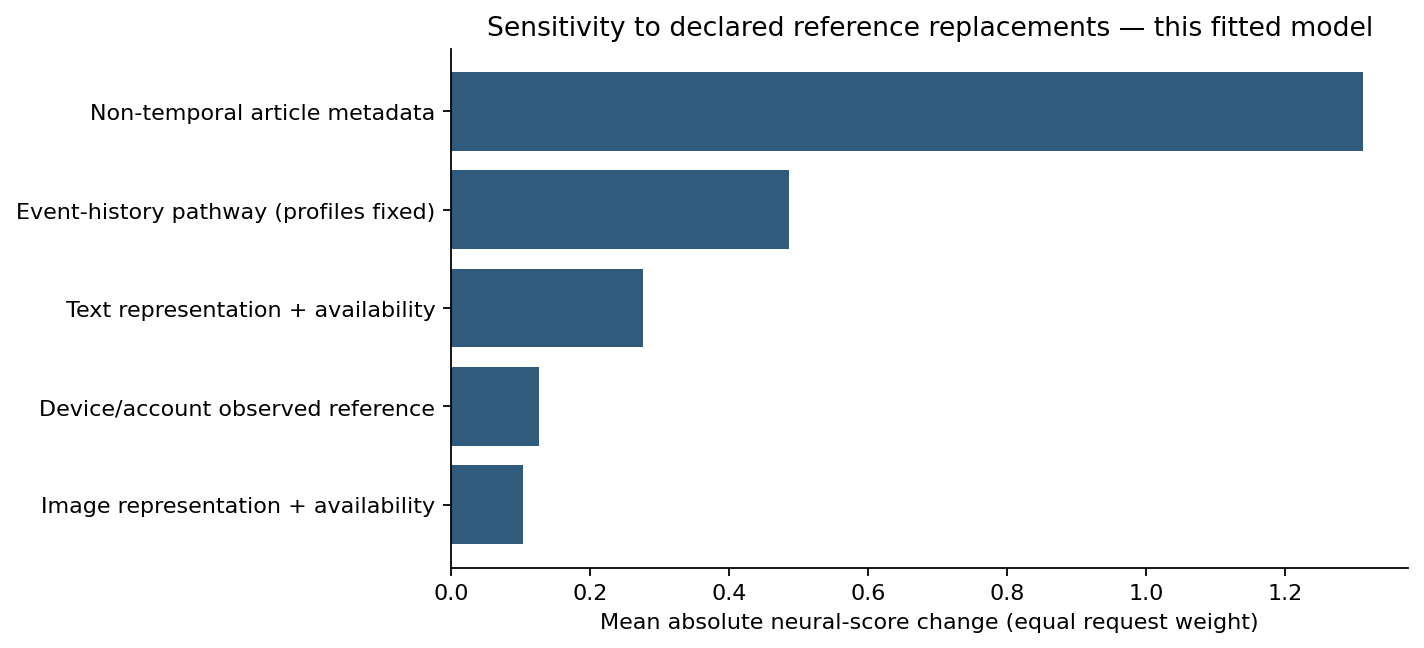

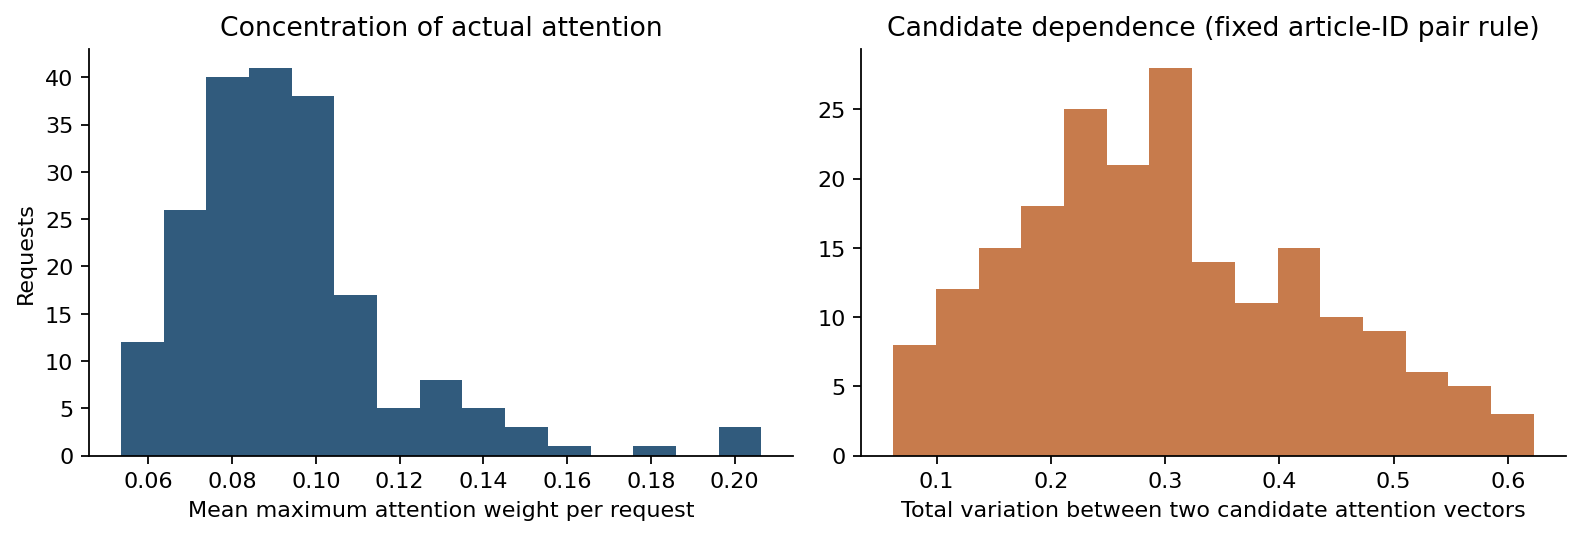

In [5]:
display(summary.assign(group_name=summary.group.map(C.GROUPS))[
    ['group_name','mean_absolute_change','mean_signed_change','requests']])
display(Image(filename=str(OUT/'figures'/'group_sensitivity.png')))
display(Image(filename=str(OUT/'figures'/'attention_diagnostics.png')))


## 7. Availability and confounding audit

Week 11's confounding discussion motivates checking how the observed data
differ from the candidate pool. Compare vector availability among all
eligible article/request pairs for these 200 requests, saved top100 articles
and observed clicks. No prediction pass is needed for this table.

Availability imbalance can help explain modality sensitivity. It does not
establish leakage, fairness or whether an unshown article would be clicked.
Current coverage also limits any claim about unseen or empty-history readers.


,population,count,No text (%),No image (%),Neither (%)
0,Eligible article/request pairs,3886220,0.092635,17.257875,0.0
1,Saved top 100,20000,0.000000,30.945000,0.0
2,Observed known clicks,201,0.000000,33.333333,0.0


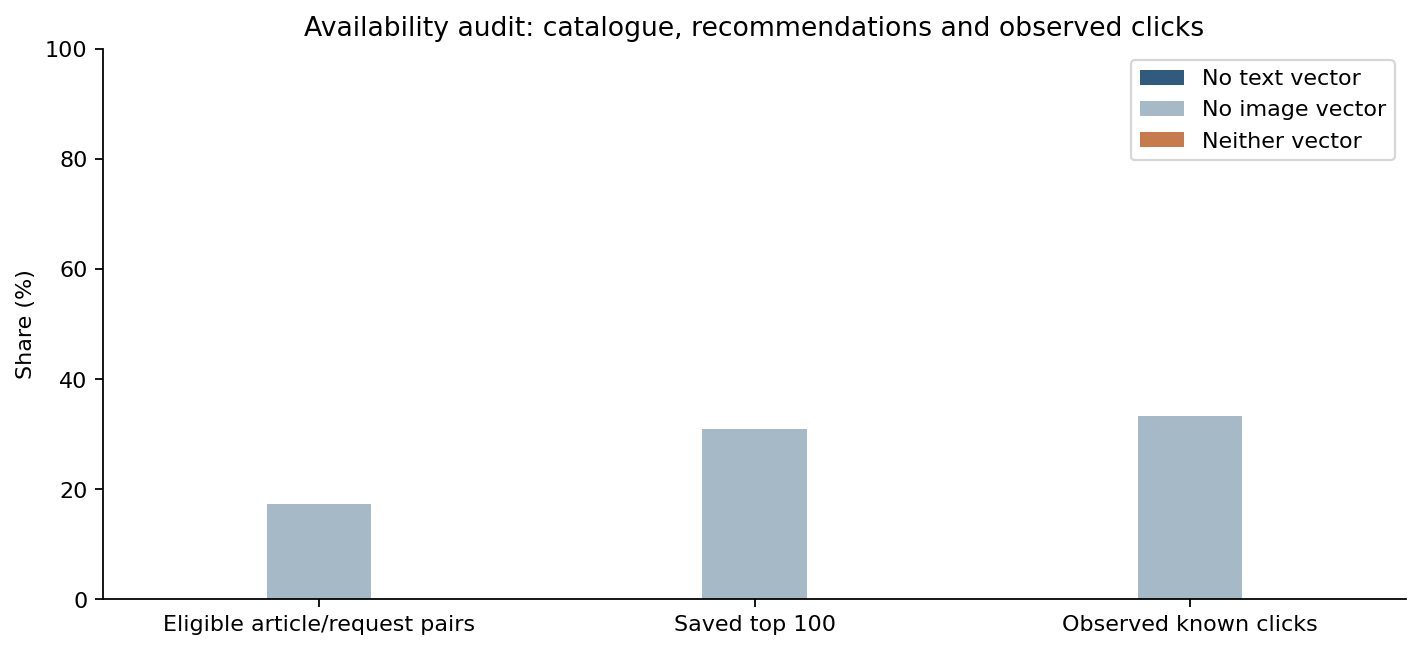

In [6]:
display(coverage.assign(no_text=coverage.no_text*100,no_image=coverage.no_image*100,
                        neither_vector=coverage.neither_vector*100).rename(columns={
    'no_text':'No text (%)','no_image':'No image (%)','neither_vector':'Neither (%)'}))
display(Image(filename=str(OUT/'figures'/'vector_coverage.png')))


## 8. Save and reload the explanation report

Save named tables, original attention arrays with aligned pair IDs, case
histories/titles, figures, cohort IDs, source fingerprints and protocol.
Keep the saved feature dictionary so interpretation does not depend on
anonymous array positions after reload. Models and evaluator files are not
copied or overwritten. Read the small persistent report back to verify that
its pair identities and attention alignment survive storage.


In [7]:
analysis_config={
    'experiment':'2.2.3_explainability','model':MODEL_NAME,'run_id':RUN_ID,
    'source_run':str(SOURCE_RUN),'source_model_files_sha256':SOURCE_DIGESTS,
    'source_score_recipe':json.loads((SOURCE_RUN/'model'/'score_recipe.json').read_text()),
    'validation_requests':len(requests),'cohort_set_sha256':COHORT_DIGEST,
    'sampling':'seed42:validation_explainability:behaviour_id, BLAKE2b-64; hash order',
    'context_reference_behaviour_id':requests.behaviour_id.iloc[0],
    'group_names':C.GROUPS,'course_references':C.COURSE_REFERENCES,
    'interpretation':'actual attention + exact age penalty; perturbations are non-additive reference sensitivity',
    'history_perturbation':'event pathway removed/recomputed; separate profile aggregates held fixed',
    'selection':'first qualifying hash-ordered request per case rule',
    'scope':'validation diagnostic sample only; no model fitting, tuning, holdout outcomes or evaluator changes',
}
C.write_json(OUT/'analysis_config.json',analysis_config)
shutil.copy2(SOURCE_RUN/'model'/'feature_dictionary.json',OUT/'source_feature_dictionary.json')
C.write_json(OUT/'helper_sources_sha256.json',{p.name:digest(p) for p in CODE_DIR.glob('*.py')})
assert SOURCE_DIGESTS=={str(p.relative_to(SOURCE_RUN)):digest(p) for p in source_files}
shutil.copytree(OUT,PERSIST,dirs_exist_ok=True)
saved=pd.read_csv(PERSIST/'explained_pairs.csv')
with np.load(PERSIST/'attention_weights.npz',allow_pickle=False) as weights:
    aligned=bool(np.array_equal(weights['article_id'],saved.article_id.to_numpy(np.int64))
                 and np.array_equal(weights['behaviour_id'],saved.behaviour_id.astype(str).to_numpy()))
reload_check={'pairs':len(saved),'pair_order_matches':bool(saved[['behaviour_id','article_id']].equals(
    baseline[['behaviour_id','article_id']].reset_index(drop=True))),
    'attention_pair_alignment':aligned,'source_files_unchanged':True}
reload_check['passed']=bool(reload_check['pair_order_matches'] and aligned and len(saved)==len(baseline))
C.write_json(PERSIST/'report_reload_check.json',reload_check)
assert reload_check['passed']
print('Report saved and reloaded:',reload_check['passed'])
print('Persistent report:',PERSIST)


Report saved and reloaded: True
Persistent report: /content/drive/MyDrive/Colab Notebooks/BT4222 Shared Final Folder/Experiments/2.2_huim/2.2.3_explainability/20261105_172058_seed42


## 9. Findings and business interpretation

The executed report below records the sample size, strongest reference
sensitivity and interpretation limits. Read it alongside the actual case
tables and plots to state what the model learned and where it struggles.
No findings are assumed in this prepared notebook.

Keep the business claims specific: which historical signals were attended,
whether deleting an event changed the score, how the age penalty reordered
the displayed articles, and where known clicks were missed. Do not infer
causal preferences, online click lift or revenue from these diagnostics.


In [8]:
display(Markdown((PERSIST/'findings.md').read_text()))


# HUIM explanation findings from this executed run

The report explains 200 fixed validation requests and
1724 shared explanation pairs. Candidate selection includes both final
models' top3, original rank100, within-buffer neural favourite and known clicked
articles. This is a conditional explanation sample, not a new ranking evaluation.

The largest request-balanced mean absolute score change followed replacement of
**Non-temporal article metadata** (1.3117 neural-score units).
This measures sensitivity to the declared reference, not intrinsic importance or
a causal effect. One-at-a-time effects need not sum to the final score. Absolute
score magnitudes from independently fitted models are not directly comparable.

Actual attention and high/low-weight event-removal results are saved for
4 cases selected by fixed rules. The event-removal score changes affect
the event-history pathway while profile aggregates remain fixed. Empty-history
requests in this cohort: 0. LSTM attention weights belong to contextual
prefix states; HUIM attention weights belong to separately encoded events.
Neither alone establishes a user's psychological motive.

The availability table compares the eligible pool, saved top100 and observed
clicks. Imbalances can confound interpretation of modality sensitivity; they do
not by themselves prove leakage or measure relevance of unexposed articles.

Freshness is an exact fitted age penalty. Input perturbations hold this explicit
term fixed, while neural weights and model selection remain unchanged. No model
was retrained, no holdout outcomes were evaluated, and no evaluator exports were
modified. Use case_candidates.csv, the top-history table and removal checks to
write the specific successful/missed recommendation interpretations.


### Course sources and project adaptations

- **Week 8:** *BT4222 26-27-T1 Topic 7 RNN and Transformer Part B*, pp24–28;
  *BT4222_Sequential_Recommendation_LSTM_with_Attention.ipynb*, source cell26
  (`explain_predictions`, readable titles and five prediction examples).
- **Week 11:** *BT4222 26T2-Topic 9 Advanced Applications of Deep Learning
  Part B*, pp16–20 and pp33–35: attention interpretation and confounding audit.
- **Week 1–2:** *BT4222 Topic 1 Introduction 26-27-T1*, pp29–32: interpretation,
  causality and the named attention/LIME/SHAP methods.
- **Week 12:** *BT4222 26T2-Topic 11 Ensemble Method*, pp15–16: model-dependent
  RF impurity importance and correlated-feature caveats. We do not apply
  that estimator directly to neural weights.

Original slides and the supplied course notebook were checked against the
generated notes. Grouped replacements, event-removal checks and exact
freshness decomposition are our adaptations to the fitted news models.
